# 04 · Expression — EMT-transcription-factor axis on the manifold

*(Renumbered from 06: with **Gate 2 = NO-GO / Gate 3 = NA** the embryonic developmental pattern is
absent, so the branching-only correlation (04) and modules (05) notebooks are **not** produced. This
unconditional EMT-TF expression step is always the final notebook, following signatures directly.)*

Puram 2017 overlays two EMT-TFs marking the ends of its trajectory. Per the **derive-don't-inherit**
mandate we score a candidate EMT-TF panel — the canonical Snail/Zeb/Twist factors **plus the
mesenchymal / neural-crest FOXC and PRRX families** (VIM is excluded — it is a mesenchymal marker,
not a transcription factor) — on *this* manifold, gated on detectable expression (>3 %), and let the
data choose the two most spatially-separated factors. Because the manifold is **non-trajectory**
here (Gate 2 NO-GO), this is a descriptive readout of where EMT-TFs sit on the malignant manifold,
not an ordering along a validated developmental axis. Deliverable: `expression.pdf`.

In [1]:
import os, sys, glob, warnings
warnings.filterwarnings('ignore')
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc
from scipy.stats import spearmanr
import matplotlib.pyplot as plt
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*4))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
os.makedirs(pth_fig, exist_ok=True)

### Load the signature-scored manifold (reads processed via signatures.h5ad)
Loads `signatures.h5ad` (carries `X_umap_lin` and pseudotime `t` from 02). Per the deliverable table
the expression step reads the processed manifold; here `signatures.h5ad` is that manifold with the
house orientation already attached, so the panel shares one orientation with 01–03.

In [3]:
adata = sc.read_h5ad(os.path.join(pth_out, 'signatures.h5ad'))
adata.obsm['X_umap'] = adata.obsm['X_umap_lin']    # house linear layout
t = adata.obs['t'].values; tn = (t-t.min())/(t.max()-t.min())
print('cells:', adata.shape[0], '| pseudotime range', round(float(t.min()),2), '->', round(float(t.max()),2))

cells: 7945 | pseudotime range 0.0 -> 9.54


### Derive the two most end-specific EMT-TFs (data-driven)
For each candidate TF: fraction of cells expressing it, mean expression in the early (root-side) vs
late pseudotime tercile, and Spearman correlation with pseudotime. Factors below a 3 % expression
floor are too sparse to overlay. The most-negative and most-positive rho factors (among expressed)
mark the two ends of the manifold's principal axis.

In [4]:
panel = ['SNAI1','SNAI2','ZEB1','ZEB2','TWIST1','TWIST2','FOXC1','FOXC2','PRRX1','PRRX2']
present = [g for g in panel if g in adata.var_names]
early = tn <= np.quantile(tn, 1/3); late = tn >= np.quantile(tn, 2/3)
X = adata[:, present].X; X = X.toarray() if hasattr(X,'toarray') else np.asarray(X)
rows = []
for j,g in enumerate(present):
    x = X[:,j]; rho,_ = spearmanr(tn, x)
    rows.append((g, round((x>0).mean(),3), round(x[early].mean(),3), round(x[late].mean(),3), round(rho,3)))
df = pd.DataFrame(rows, columns=['TF','frac_expr','mean_early','mean_late','rho_vs_t']).sort_values('rho_vs_t')
print(df.to_string(index=False))
ok = df[df.frac_expr > 0.03]
early_tf = ok.iloc[0]['TF']; late_tf = ok.iloc[-1]['TF']
print(f'\nderived pair: {early_tf} (root-side) <-> {late_tf} (far end)')

    TF  frac_expr  mean_early  mean_late  rho_vs_t
  ZEB1      0.088       0.043      0.034    -0.025
 FOXC1      0.171       0.084      0.089    -0.006
 FOXC2      0.002       0.000      0.000     0.005
TWIST2      0.000       0.000      0.000     0.028
 PRRX2      0.039       0.008      0.018     0.040
TWIST1      0.008       0.001      0.005     0.051
 SNAI1      0.023       0.006      0.014     0.064
 PRRX1      0.022       0.004      0.014     0.067
  ZEB2      0.058       0.013      0.034     0.084
 SNAI2      0.093       0.013      0.098     0.224

derived pair: ZEB1 (root-side) <-> SNAI2 (far end)


### EMT-TF expression overlay (deliverable)
House style: `figsize=(3.5,1.5)`, `size=30`, **categorical thresholded-expresser overlay on a grey
manifold** (not a continuous colormap). Each factor is thresholded at the upper quartile of
expression among its expressing cells; the more widely-expressed factor is drawn first and the
sparser one on top so neither is occluded. Blue = root-side factor, red = far-end factor.

ZEB1: 8.8% expressing; 175 shown (upper quartile), mean pseudotime of shown = 0.45 (all = 0.47)
SNAI2: 9.3% expressing; 184 shown (upper quartile), mean pseudotime of shown = 0.75 (all = 0.47)
saved expression.pdf


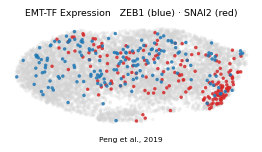

In [5]:
xl = adata.obsm['X_umap']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
def _vec(g):
    x = adata[:,g].X; return x.toarray().ravel() if hasattr(x,'toarray') else np.asarray(x).ravel()
thr = {}
for g in [early_tf, late_tf]:
    v = _vec(g); pos = v[v>0]; thr[g] = float(np.quantile(pos,0.75)) if pos.size else 0.0
sel = {g: _vec(g) > thr[g] for g in [early_tf, late_tf]}
order = sorted([early_tf, late_tf], key=lambda g: -int(sel[g].sum()))
colors = {early_tf:'tab:blue', late_tf:'tab:red'}
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(adata, size=30, alpha=.3, frameon=False, show=False, ax=ax, na_color='lightgray')
for g in order:
    ap = adata[sel[g]].copy()
    sc.pl.umap(ap, na_color=colors[g], size=30, alpha=.85, frameon=False, show=False, ax=ax)
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.set_title(f'EMT-TF Expression   {early_tf} (blue) · {late_tf} (red)', size=7.5)
ax.text(.5,-.14,'Peng et al., 2019', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'expression.pdf'), bbox_inches='tight')
for g in [early_tf, late_tf]:
    m = sel[g]
    print(f'{g}: {(_vec(g)>0).mean()*100:.1f}% expressing; {int(m.sum())} shown (upper quartile), '
          f'mean pseudotime of shown = {tn[m].mean():.2f} (all = {tn.mean():.2f})')
print('saved expression.pdf')